In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
N = 1000000
rng = np.random.default_rng(42)

In [3]:
x = rng.uniform(-1, 1, size=N)
y = rng.uniform(-1, 1, size=N)

In [4]:
print(x.shape, y.shape)
print(x.min(), x.max())

(1000000,) (1000000,)
-0.9999997499935342 0.9999994344071144


In [5]:
d2 = x**2 + y**2
print(d2.shape)
print(d2.min(), d2.max())

(1000000,)
3.79719098248949e-07 1.9983175296069386


In [6]:
inside = d2 <= 1
print(inside.shape, inside.dtype)
print(inside[:10])
print(inside.sum())
print("\n*****************************\n")
I = inside.astype(float)
print(I[:10])
print(I.mean())
# dispersiyani hisoblash
print("\n=== Bernulli natijasining dispersiyasi ===")
p_hat = I.mean()
var_direct = ((I - p_hat) ** 2).mean()
print("p =", p_hat)
print(var_direct)
print(I.var())      # numpy ning tayyor funksiyasi
print(p_hat*(1-p_hat))

(1000000,) bool
[ True  True False  True  True False  True  True False  True]
785445

*****************************

[1. 1. 0. 1. 1. 0. 1. 1. 0. 1.]
0.785445

=== Bernulli natijasining dispersiyasi ===
p = 0.785445
0.16852115197499995
0.16852115197499995
0.16852115197500003


In [7]:
print("\n=== pi ni hisoblash ===")
pi_est = 4 * (inside.sum() / N)
print(pi_est)
print(np.pi)
print(abs(pi_est - np.pi))


=== pi ni hisoblash ===
3.14178
3.141592653589793
0.00018734641020667908


N ga bog'liqlik

In [8]:
print("\n=== N ga bog'liqlik ===\n")
def estimate_pi(n, rng):
    x = rng.uniform(-1, 1, size=n)
    y = rng.uniform(-1, 1, size=n)
    d2 = x**2 + y**2
    inside = d2 <= 1
    p_hat = inside.mean()
    baho = 4 * p_hat
    se = 4 * np.sqrt(p_hat * (1 - p_hat) / n)
    return baho, se


=== N ga bog'liqlik ===



In [9]:
baho, se = estimate_pi(100, rng)
print(baho, se, abs(baho - np.pi))

3.28 0.1536749816983884 0.1384073464102067


In [10]:
baho, se = estimate_pi(10_000, rng)
print(baho, se, abs(baho - np.pi))

3.1488 0.016371495227986966 0.007207346410206927


In [11]:
baho, se = estimate_pi(1_000_000, rng)
print(baho, se, abs(baho - np.pi))

3.139892 0.001643364301771217 0.0017006535897929886


In [12]:
print("\n=== 2D massivga joylash ===\n")


=== 2D massivga joylash ===



In [13]:
def estimate_pi_many(n, R, rng):
    x = rng.uniform(-1, 1, size=(R, n))
    y = rng.uniform(-1, 1, size=(R, n))
    d2 = x**2 + y**2
    inside = d2 <= 1
    return 4 * (inside.sum(axis=1) / n)

In [14]:
est = estimate_pi_many(100, 200, rng)
print(est.shape)
print(est.mean())
print(est.std())

(200,)
3.1490000000000005
0.14526871652217485


In [15]:
print("\n=== Turli N lar uchun o'rtacha xatolik ===\n")


=== Turli N lar uchun o'rtacha xatolik ===



In [16]:
Ns = np.array([10**2, 10**3, 10**4, 10**5])
R = 100
errors = np.array([np.abs(estimate_pi_many(n, R, rng) - np.pi).mean() for n in Ns])
print(errors)
print(errors[:-1] / errors[1:])

[0.13836815 0.03277629 0.01200341 0.00443895]
[4.22159221 2.73058136 2.70411259]


In [17]:
print("\n=== SE tekshiruvi ===")
print((I**2 == I).all())


=== SE tekshiruvi ===
True


In [18]:
n = 100
se_theory = 4 * np.sqrt(p_hat * (1 - p_hat) / n)
print("nazariy SE:", se_theory)

nazariy SE: 0.16420531147316766


In [19]:
est_big = estimate_pi_many(n, 20_000, rng)
print("haqiqiy tebranish:", est_big.std())

haqiqiy tebranish: 0.16540165221665712


Grafik chizish

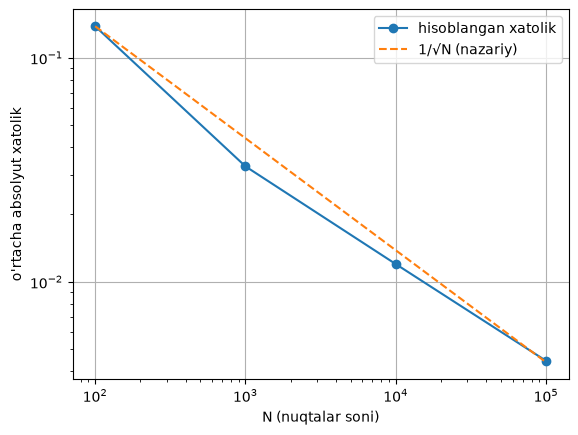

In [20]:
plt.loglog(Ns, errors, "o-", label="hisoblangan xatolik")
plt.loglog(Ns, errors[0] * np.sqrt(Ns[0] / Ns), "--", label="1/√N (nazariy)")
plt.xlabel("N (nuqtalar soni)")
plt.ylabel("o'rtacha absolyut xatolik")
plt.legend()
plt.grid(True)
plt.savefig("../../notebooks/01_pi.png", dpi=150)

In [21]:
slope = np.polyfit(np.log10(Ns), np.log10(errors), 1)[0]
print(slope)

-0.49175236376737
